# RQ6: Audio profile: gloomy vs clear days

**Question:** What is the characteristic audio profile (valence, energy, danceability, acousticness, tempo) of the German Spotify charts on **gloomy** days (dark + wet) compared to **clear** days (sunny + dry)?

Reporting layer over the `Workflow 6` Snakemake outputs: it reads the results and adds interpretation. The analysis itself lives in the tested components under `src/Workflow 6/`.

## Method (in brief)

1. Aggregate the charts to a **daily** audio profile (mean of each feature) together with that day's weather.
2. Label each day **gloomy** / **clear** / **other** using percentile cut-points of daily sunshine and precipitation (`utils.label_gloomy_clear`). Percentiles are used instead of the README's literal "0 sunshine / >2 mm" definition because our sunshine is a national average across DWD stations and is almost never exactly 0.
3. Compare each feature's mean between gloomy and clear days with a **Mann-Whitney U** test.
4. Visualise the two mean profiles as a radar chart (features min-max normalized so tempo and the 0–1 features are comparable).

## How to reproduce

```bash
cd "src/Workflow 6"
snakemake -s SnakefileWorkflow6 --cores 1
```

This regenerates `results/workflow_6/profile_comparison.csv` and `audio_profile_radar.png`, which the cells below load.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RESULTS = Path("..") / "results" / "workflow_6"
comp = pd.read_csv(RESULTS / "profile_comparison.csv")
comp

,feature,gloomy_mean,clear_mean,diff_gloomy_minus_clear,u_statistic,p_value,significant
0,valence,0.4902,0.4954,-0.0052,21149.0,0.5153,False
1,energy,0.6566,0.6771,-0.0205,14764.5,0.0000,True
2,danceability,0.6796,0.6863,-0.0068,18046.5,0.0017,True
3,acousticness,0.1958,0.2017,-0.0058,18854.5,0.0127,True
4,tempo,116.9133,117.9273,-1.0140,18601.5,0.0070,True


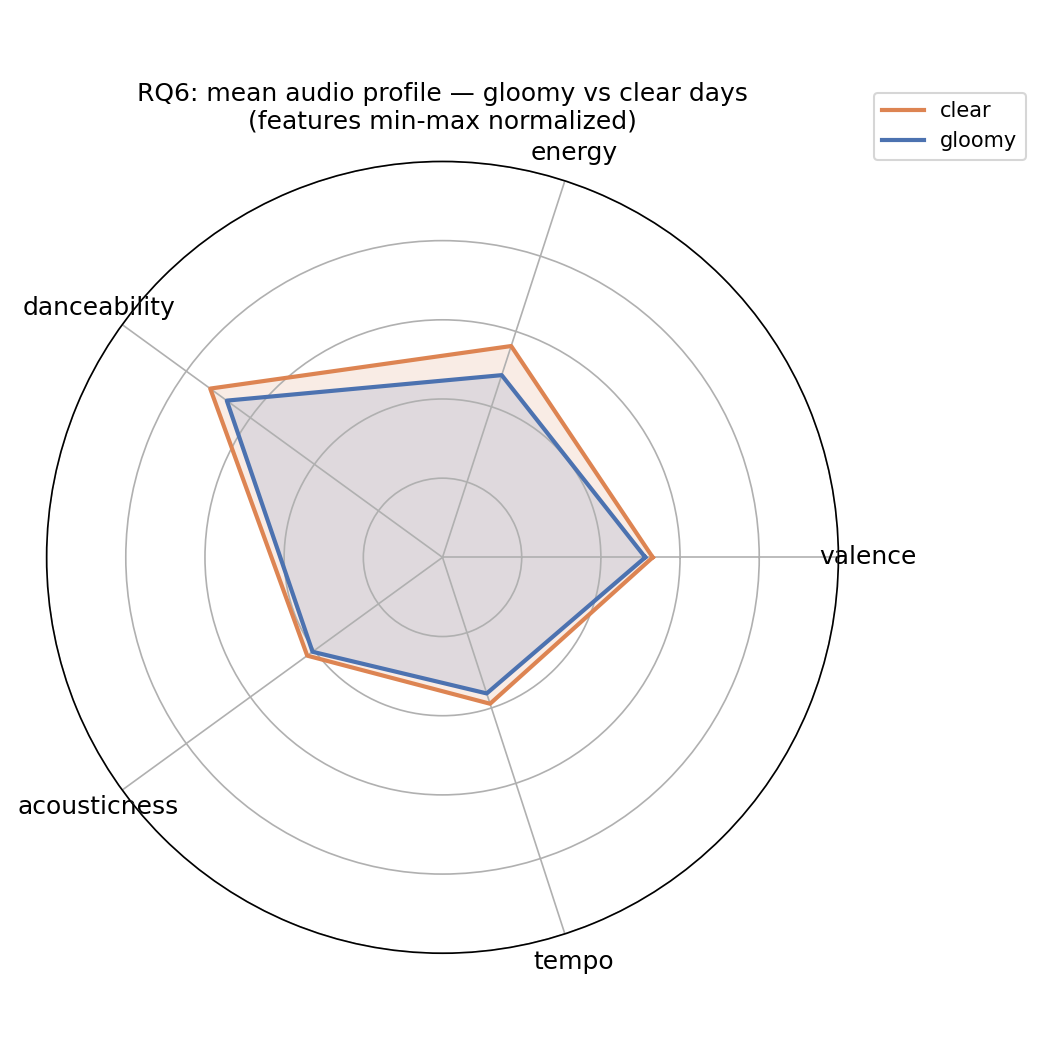

In [2]:
display(Image(filename=str(RESULTS / "audio_profile_radar.png")))

## Findings

- **The two profiles are remarkably similar** — the gloomy and clear radar polygons almost overlap. Weather does not reshape what the charts sound like.
- **Valence (musical positivity) does not differ**: gloomy 0.490 vs clear 0.495, p = 0.52 (not significant). The charts are *not* measurably "sadder" on gloomy days.
- **Clear days are marginally more energetic / danceable / faster:** energy +0.021 (p < 0.001), danceability +0.007 (p = 0.002), tempo +1.0 BPM (p = 0.007), acousticness +0.006 (p = 0.013) — all higher on clear days.
- Effects are **statistically significant but tiny** (≤ 0.02 on a 0–1 scale; ~1 BPM), driven by the large sample (183 gloomy + 240 clear days).

Direction: sunnier/drier days lean *very slightly* more upbeat — but the magnitude is small and, given the confound below, likely seasonal.

## Caveats

- **Season confound (large):** gloomy days are mostly winter (DJF), clear days mostly spring/summer (MAM/JJA), so this is partly a winter-vs-summer comparison rather than a pure weather effect.
- **Small effect sizes:** significance is driven by sample size; practical differences are minor. Acousticness is *slightly higher* on clear days, which is mildly counterintuitive but tiny.
- **Definition:** gloomy/clear use percentile cut-points (sun ≤ P25 & precip ≥ P75; sun ≥ P75 & precip ≤ P25), adapting the README's single-station definition to our national-average data.
- **Aggregation:** the daily profile is the simple mean of the day's charting tracks' features (not stream-weighted).

## Takeaway

The charts' audio profile is largely **weather-invariant**: gloomy and clear days sound almost the same. Valence is unchanged, and while clear days are marginally more energetic/danceable/faster (all statistically significant), the effects are small and confounded with season. So weather has at most a subtle association with the sound of the German charts.